<a href="https://colab.research.google.com/github/julianakcm1/letalidade-motociclistas-nordeste-prf/blob/main/motociclistas_nordeste_PRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mortes de motociclistas nas rodovias federais do Nordeste (2021–2025)

**Disciplina:** Ciência de Dados · **Professor:** Bruno Pimentel · **Discente:** Juliana Baracho

**Pergunta de decisão:** em quais situações e para quais perfis de motociclista um acidente nas rodovias federais do Nordeste tem mais chance de terminar em morte, e onde a PRF e os órgãos de trânsito devem concentrar fiscalização, campanhas e obras?

**O porquê do tema:** mais de 40% das mortes no trânsito do país são de motociclistas (41,6% em 2024)

**Hipóteses:**
* **H1:** o tipo de acidente é o fator mais associado à morte.
* **H2:** acidentes à noite e no amanhecer são mais letais que os de dia.
* **H3:** a diferença de letalidade entre os estados muda quando se considera o tipo de acidente, o horário e a via.

**O que vai ser feito:**
1. Baixo os dados abertos da PRF de 2021 a 2025 (uma linha por pessoa envolvida).
2. Filtro só os motociclistas (condutores e garupas) acidentados nos estados do Nordeste.
3. Limpo os dados e crio variáveis.
4. Exploro: quem morre mais? Em que horário, tipo de acidente e estado?
5. Treino modelos que estimam a chance de morte e comparo os estados em igualdade de condições.

## 1. Imports

In [73]:
import os
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown

from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

pd.set_option("display.max_columns", 60)
SEED = 42

## 2. Download

Fonte: [Dados abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf)

In [74]:
# códigos dos arquivos agrupados por pessoa no Google Drive da PRF (copiados do portal de dados abertos)
arquivos_drive = {
    2021: "15W_l07-6taOh8Ycn8uk2Er9PnSj0vq3f",
    2022: "1sd8YIqIHapYaxQeaa-6yeWMdVLTl6hgD",
    2023: "1-Yk6TV00CH3PixTkKmkoUJQsNiUc5xLm",
    2024: "14lVfqdoE2gxDliaKZu7K9Mx6847maPtl",
    2025: "1-Gp9S-ALO0D1nT8S_OKoC8xlW7BY8F82",
}

for ano, codigo in arquivos_drive.items():
    nome = f"prf_pessoa_{ano}.zip"
    if os.path.exists(nome):
        print(ano, "já estava baixado")
    else:
        gdown.download(id=codigo, output=nome, quiet=True)
        print(ano, "baixado")

2021 já estava baixado
2022 já estava baixado
2023 já estava baixado
2024 já estava baixado
2025 já estava baixado


In [75]:
def ler_prf(nome):
    # o arquivo pode vir como .zip ou .csv; e a codificação varia entre os anos
    if zipfile.is_zipfile(nome):
        with zipfile.ZipFile(nome) as z:
            csv = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            conteudo = z.read(csv)
    else:
        conteudo = open(nome, "rb").read()
    for codificacao in ["utf-8", "latin-1"]:
        try:
            return pd.read_csv(io.BytesIO(conteudo), sep=";", encoding=codificacao, decimal=",", low_memory=False)
        except UnicodeDecodeError:
            continue

partes = []
for ano in arquivos_drive:
    tabela = ler_prf(f"prf_pessoa_{ano}.zip")
    tabela["ano"] = ano
    partes.append(tabela)
    print(ano, tabela.shape)

df = pd.concat(partes, ignore_index=True)

2021 (166287, 36)
2022 (170825, 36)
2023 (183361, 36)
2024 (196448, 36)
2025 (194629, 36)


In [76]:
print("total:", df.shape)

total: (911550, 36)


* 911.550 pessoas envolvidas em acidentes (2021-2025)

In [77]:
df

,id,pesid,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,classificacao_acidente,fase_dia,sentido_via,condicao_metereologica,tipo_pista,tracado_via,uso_solo,id_veiculo,tipo_veiculo,marca,ano_fabricacao_veiculo,tipo_envolvido,estado_fisico,idade,sexo,ilesos,feridos_leves,feridos_graves,mortos,latitude,longitude,regional,delegacia,uop,ano
0,331730.0,738258,2021-01-01,sexta-feira,05:30:00,SP,116,453.0,REGISTRO,Reação tardia ou ineficiente do condutor,Tombamento,Com Vítimas Feridas,Amanhecer,Crescente,Nublado,Dupla,Curva,Não,595150,Caminhão,VOLVO/VM 260 6X2R/VM 260 6X2R,2010,Condutor,Lesões Leves,35,Masculino,0,1,0,0,-24.561681,-47.867522,SPRF-SP,DEL05-SP,UOP01-DEL05-SP,2021
1,331804.0,738412,2021-01-01,sexta-feira,08:05:00,AM,174,937.0,MANAUS,Reação tardia ou ineficiente do condutor,Colisão traseira,NaN,Pleno dia,Crescente,Céu Claro,Simples,Reta,Não,595262,Caminhão-trator,SCANIA/R112 H/R112 H,1982,Condutor,Ileso,65,Masculino,1,0,0,0,-2.508068,-60.036434,SPRF-AM,DEL01-AM,UOP01-DEL01-AM,2021
2,331815.0,738689,2021-01-01,sexta-feira,10:10:00,CE,222,128.5,ITAPAJE,Velocidade Incompatível,Tombamento,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Simples,Curva,Não,595291,Caminhão-trator,SCANIA/R124 GA4X2NZ 360/R124 GA4X2NZ 360,1999,Condutor,Lesões Leves,35,Masculino,0,1,0,0,-3.707626,-39.623509,SPRF-CE,DEL04-CE,UOP03-DEL04-CE,2021
3,331815.0,738692,2021-01-01,sexta-feira,10:10:00,CE,222,128.5,ITAPAJE,Velocidade Incompatível,Tombamento,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Simples,Curva,Não,595291,Caminhão-trator,SCANIA/R124 GA4X2NZ 360/R124 GA4X2NZ 360,1999,Passageiro,Lesões Leves,0,Feminino,0,1,0,0,-3.707626,-39.623509,SPRF-CE,DEL04-CE,UOP03-DEL04-CE,2021
4,331823.0,740272,2021-01-01,sexta-feira,12:30:00,RJ,493,18.0,MAGE,Ingestão de álcool e/ou substâncias psicoativa...,Colisão lateral,Com Vítimas Feridas,Pleno dia,Decrescente,Nublado,Simples,Curva,Sim,595234,Caminhão-trator,VOLVO/FH 460 6X2T/FH 460 6X2T,2017,Condutor,Ileso,51,Masculino,1,0,0,0,-22.668712,-43.018627,SPRF-RJ,DEL04-RJ,UOP02-DEL04-RJ,2021
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
911545,757593.0,1701493,2025-12-14,domingo,13:50:00,PE,104,62.0,CARUARU,Ausência de reação do condutor,Colisão transversal,Com Vítimas Feridas,Pleno dia,Crescente,Céu Claro,Dupla,Reta,Sim,1354580,Automóvel,VW/FOX 1.0 GII,2009,Condutor,Ileso,41,Masculino,1,0,0,0,-8.253680,-35.975460,SPRF-PE,DEL02-PE,UOP01-DEL02-PE,2025
911546,758175.0,1702860,2025-12-15,segunda-feira,15:50:00,SC,101,130.0,CAMBORIU,Condutor deixou de manter distância do veículo...,Colisão traseira,Sem Vítimas,Pleno dia,Crescente,Sol,Dupla,Reta,Sim,1355745,Automóvel,I/RENAULT FLUENCE PRI20A,2010,Condutor,Ileso,64,Masculino,1,0,0,0,-26.993060,-48.660955,SPRF-SC,DEL04-SC,UOP03-DEL04-SC,2025
911547,758175.0,1702859,2025-12-15,segunda-feira,15:50:00,SC,101,130.0,CAMBORIU,Condutor deixou de manter distância do veículo...,Colisão traseira,Sem Vítimas,Pleno dia,Crescente,Sol,Dupla,Reta,Sim,1355744,Caminhonete,RENAULT/MASTER L3 FUT A,2023,Condutor,Ileso,31,Masculino,1,0,0,0,-26.993060,-48.660955,SPRF-SC,DEL04-SC,UOP03-DEL04-SC,2025
911548,758186.0,1702906,2025-11-02,domingo,23:00:00,MG,381,218.3,BELO ORIENTE,Acessar a via sem observar a presença dos outr...,Colisão traseira,Com Vítimas Feridas,Plena Noite,Decrescente,Nublado,Simples,Reta;Interseção de Vias,Não,1355780,Automóvel,FIAT/UNO WAY 1.0,2011,Condutor,Lesões Graves,47,Masculino,0,0,1,0,-19.298811,-42.371921,SPRF-MG,DEL06-MG,UOP01-DEL06-MG,2025


In [78]:
print(df.columns.tolist())

['id', 'pesid', 'data_inversa', 'dia_semana', 'horario', 'uf', 'br', 'km', 'municipio', 'causa_acidente', 'tipo_acidente', 'classificacao_acidente', 'fase_dia', 'sentido_via', 'condicao_metereologica', 'tipo_pista', 'tracado_via', 'uso_solo', 'id_veiculo', 'tipo_veiculo', 'marca', 'ano_fabricacao_veiculo', 'tipo_envolvido', 'estado_fisico', 'idade', 'sexo', 'ilesos', 'feridos_leves', 'feridos_graves', 'mortos', 'latitude', 'longitude', 'regional', 'delegacia', 'uop', 'ano']


**Variáveis principais:**

*   `id`: código do acidente (várias pessoas podem ter o mesmo id)
*   `uf`, `br`, `km`, `municipio`: onde aconteceu o acidente
*   `data_inversa`, `dia_semana`, `horario`, `fase_dia`: quando aconteceu o acidente
*   `causa_acidente`, `tipo_acidente`: causa e tipo do acidente (se foi colisão, queda, etc)
*   `condicao_metereologica`, `tipo_pista`, `tracado_via`, `uso_solo`, `sentido_via`: condições do local
*   `tipo_veiculo`, `ano_fabricacao_veiculo`, `id_veiculo`: veículo da pessoa
*   `tipo_envolvido`, `idade`, `sexo`: identificação da pessoa
*   `estado_fisico`: se lesão, óbito, ileso.


**O que não vai entrar no modelo para não haver vazamento de dados:** `mortos`, `feridos_leves`, `feridos_graves`, `ilesos` e `classificacao_acidente`. Essas colunas contam as vítimas do próprio acidente, ou seja, já trazem a resposta que eu quero prever.




## 3. Recorte - Motociclistas no Nordeste

In [79]:
print(df['tipo_veiculo'].unique())

['Caminhão' 'Caminhão-trator' 'Semireboque' 'Reboque' 'Automóvel'
 'Camioneta' 'Utilitário' 'Outros' 'Motocicleta' 'Ônibus' 'Motoneta'
 'Trator de rodas' 'Caminhonete' 'Quadriciclo' 'Carroça-charrete'
 'Trator de esteira' 'Bicicleta' nan 'Micro-ônibus' 'Ciclomotor'
 'Carro de mão' 'Triciclo' 'Motor-casa' 'Chassi-plataforma' 'Trem-bonde'
 'Trator misto']


In [80]:
nordeste = ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]

etapas = [("Pessoas envolvidas (Brasil, 2021–2025)", len(df))]

base = df[df["uf"].isin(nordeste)] # mantendo só os estados do Nordeste
etapas.append(("Acidente em estado do Nordeste", len(base)))

base = base[base["tipo_veiculo"].isin(["Motocicleta", "Motoneta", "Ciclomotor"])]
etapas.append(("Estava numa moto, motoneta ou ciclomotor", len(base)))

base = base[base["tipo_envolvido"].isin(["Condutor", "Passageiro"])]
etapas.append(("Condutor ou garupa", len(base)))

# tirando quem não tem o estado físico informado porque é ele quem informa se houve morte
base = base[base["estado_fisico"].notna() & ~base["estado_fisico"].astype(str).str.contains("Não Informado|Nao Informado", case=False)]
etapas.append(("Estado físico informado", len(base)))

pd.DataFrame(etapas, columns=["Etapa", "Linhas que sobraram"])

,Etapa,Linhas que sobraram
0,"Pessoas envolvidas (Brasil, 2021–2025)",911550
1,Acidente em estado do Nordeste,194999
2,"Estava numa moto, motoneta ou ciclomotor",50272
3,Condutor ou garupa,50241
4,Estado físico informado,48209


* 48.209 motociclistas no Nordeste

In [81]:
base["estado_fisico"].value_counts()

,count
estado_fisico,
Lesões Leves,27244
Lesões Graves,13839
Óbito,3895
Ileso,3231


* **Letalidade:** 8,1% (3.895 óbitos entre 48.209 motociclistas acidentados).
* Lesões leves são o desfecho mais comum (27.244), seguidas de lesões graves (13.839).

### Limpeza e criação das variáveis

#### Alvo

In [82]:
base = base.copy()

# o que quero prever: 1 = morreu, 0 = sobreviveu
base["morte"] = base["estado_fisico"].astype(str).str.contains("bito").astype(int) # para tirar o acento da busca (Óbito)

print(f"letalidade entre motociclistas acidentados: {base['morte'].mean():.1%}")
print(base["morte"].value_counts())

letalidade entre motociclistas acidentados: 8.1%
morte
0    44314
1     3895
Name: count, dtype: int64


A morte é um evento raro, então um modelo dizer sempre "não morreu" acertaria bastante. Acurácia não será a melhor métrica.

#### Nulos e outliers

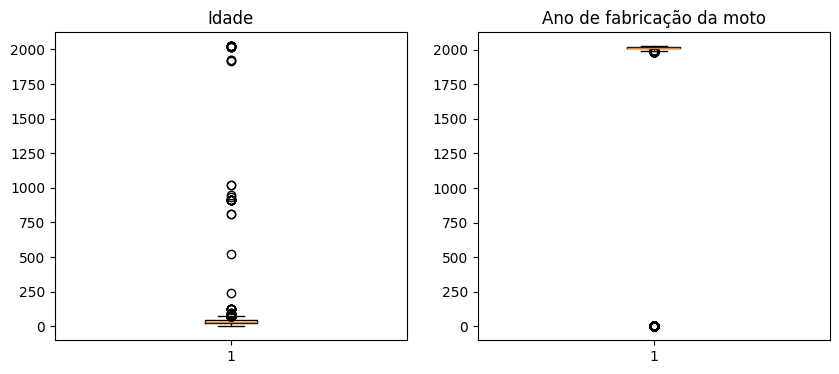

idade: 358 outliers | mínimo = 0 | máximo = 2023 | vazios = 0
ano_fabricacao_veiculo: 4952 outliers | mínimo = 0 | máximo = 2025 | vazios = 0


In [83]:
base["idade"] = pd.to_numeric(base["idade"], errors="coerce")
base["ano_fabricacao_veiculo"] = pd.to_numeric(base["ano_fabricacao_veiculo"], errors="coerce") # convertendo a idade e o ano de fabric. para número

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].boxplot(base["idade"].dropna())
ax[0].set_title("Idade")
ax[1].boxplot(base["ano_fabricacao_veiculo"].dropna())
ax[1].set_title("Ano de fabricação da moto")
plt.show()

for c in ["idade", "ano_fabricacao_veiculo"]:
    q1, q3 = base[c].quantile(0.25), base[c].quantile(0.75)
    iqr = q3 - q1
    fora = ((base[c] < q1 - 1.5 * iqr) | (base[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {fora} outliers | mínimo = {base[c].min():.0f} | máximo = {base[c].max():.0f} | vazios = {base[c].isna().sum()}")

* **Idade:** idades acima de 100 ou abaixo de 1 são erro de registro, então viram vazio. Idades altas, mas possíveis, ficam.
* **Ano de fabricação:** anos antes de 1950 ou depois do ano do acidente são impossíveis e viram vazio. Com o ano válido, calculo a **idade da moto**.
* Os zeros nas duas variáveis são, na prática, "não informado". E valores como idade = 2023 provavelmente são anos digitados no campo errado.

In [84]:
base.loc[(base["idade"] < 1) | (base["idade"] > 100), "idade"] = np.nan

invalido = (base["ano_fabricacao_veiculo"] < 1950) | (base["ano_fabricacao_veiculo"] > base["ano"])
base.loc[invalido, "ano_fabricacao_veiculo"] = np.nan
base["idade_moto"] = base["ano"] - base["ano_fabricacao_veiculo"]

print("idades vazias:", base["idade"].isna().sum())
print("idade da moto vazia:", base["idade_moto"].isna().sum())

idades vazias: 1672
idade da moto vazia: 4842


#### Novas variáveis

In [85]:
# hora do acidente (o horário vem como "00:00:00"), então pego os 2 primeiros caracteres (hora)
base["hora"] = pd.to_numeric(base["horario"].astype(str).str[:2], errors="coerce")

# data: "2023-05-01" e "01/05/2023"; testo os dois formatos e o texto da data em data de verdade
data = pd.to_datetime(base["data_inversa"], format="%Y-%m-%d", errors="coerce")
data = data.fillna(pd.to_datetime(base["data_inversa"], format="%d/%m/%Y", errors="coerce"))
print("datas não lidas:", data.isna().sum())  # se não for 0, essas linhas viram "não" no fim de semana
base["mes"] = data.dt.month
base["fim_de_semana"] = np.where(data.dt.dayofweek >= 5, "sim", "não")

# faixa etária: dividindo em faixas
base["faixa_etaria"] = pd.cut(base["idade"], bins=[0, 17, 24, 34, 49, 100],
                              labels=["até 17", "18 a 24", "25 a 34", "35 a 49", "50 ou mais"]).astype(str)

# confiro se a mesma pessoa aparece mais de uma vez (o esperado é 0)
print("pessoas repetidas:", base["pesid"].duplicated().sum())

# vendo se o acidente envolveu outro veículo além da moto
veiculos_por_acidente = df.groupby("id")["id_veiculo"].nunique()
base["outro_veiculo"] = np.where(base["id"].map(veiculos_por_acidente) > 1, "sim", "não")

# em alguns anos o traçado vem com mais de um valor ("Reta;Declive"); fico com o primeiro
base["tracado_via"] = base["tracado_via"].astype(str).str.split(";").str[0]

# causas e tipos de acidente têm dezenas de categorias: mantenho as 12 mais comuns e junto o resto em "outras"
for c in ["causa_acidente", "tipo_acidente"]:
    principais = base[c].value_counts().index[:12]
    base[c + "_grupo"] = np.where(base[c].isin(principais), base[c], "outras")

# textos vazios viram "ignorado"
categoricas = ["sexo", "tipo_envolvido", "uf", "fase_dia", "fim_de_semana", "condicao_metereologica",
               "tipo_pista", "tracado_via", "uso_solo", "tipo_acidente_grupo", "causa_acidente_grupo",
               "faixa_etaria", "outro_veiculo"]
for c in categoricas:
    base[c] = base[c].astype(str).replace({"nan": "ignorado", "None": "ignorado", "": "ignorado"})

base[["morte", "idade", "faixa_etaria", "sexo", "tipo_envolvido", "uf", "hora", "fase_dia",
      "tipo_acidente_grupo", "outro_veiculo", "idade_moto"]].head(10)

datas não lidas: 0
pessoas repetidas: 0


,morte,idade,faixa_etaria,sexo,tipo_envolvido,uf,hora,fase_dia,tipo_acidente_grupo,outro_veiculo,idade_moto
38552,0,33.0,25 a 34,Masculino,Condutor,PE,0,Plena Noite,Colisão traseira,sim,3.0
38579,1,25.0,25 a 34,Masculino,Condutor,PE,3,Plena Noite,Colisão frontal,sim,8.0
38584,1,44.0,35 a 49,Masculino,Condutor,PE,2,Plena Noite,Atropelamento de Animal,não,NaN
38585,0,40.0,35 a 49,Feminino,Passageiro,PE,2,Plena Noite,Atropelamento de Animal,não,NaN
38593,1,34.0,25 a 34,Masculino,Condutor,PE,4,Amanhecer,Tombamento,não,5.0
38611,0,54.0,50 ou mais,Masculino,Condutor,BA,4,Amanhecer,Atropelamento de Animal,não,10.0
38618,0,NaN,ignorado,Feminino,Passageiro,SE,6,Pleno dia,Tombamento,não,30.0
38619,0,27.0,25 a 34,Masculino,Condutor,SE,6,Pleno dia,Tombamento,não,30.0
38665,0,21.0,18 a 24,Masculino,Condutor,AL,11,Pleno dia,Saída de leito carroçável,não,12.0
38684,0,31.0,25 a 34,Masculino,Condutor,CE,12,Pleno dia,Colisão traseira,sim,11.0


In [86]:
# quanto da idade da moto ficou vazio, no total e por ano
print(f"idade da moto vazia: {base['idade_moto'].isna().mean():.1%}")
base.groupby("ano")["idade_moto"].apply(lambda s: s.isna().mean()).mul(100).round(1)

idade da moto vazia: 10.0%


,idade_moto
ano,
2021,11.2
2022,10.9
2023,9.5
2024,9.9
2025,9.1


In [87]:
# quanto da idade ficou vazio, no total e por ano
print(f"idade vazia: {base['idade'].isna().mean():.1%}")
base.groupby("ano")["idade"].apply(lambda s: s.isna().mean()).mul(100).round(1)

idade vazia: 3.5%


,idade
ano,
2021,4.1
2022,3.8
2023,3.0
2024,3.6
2025,3.0


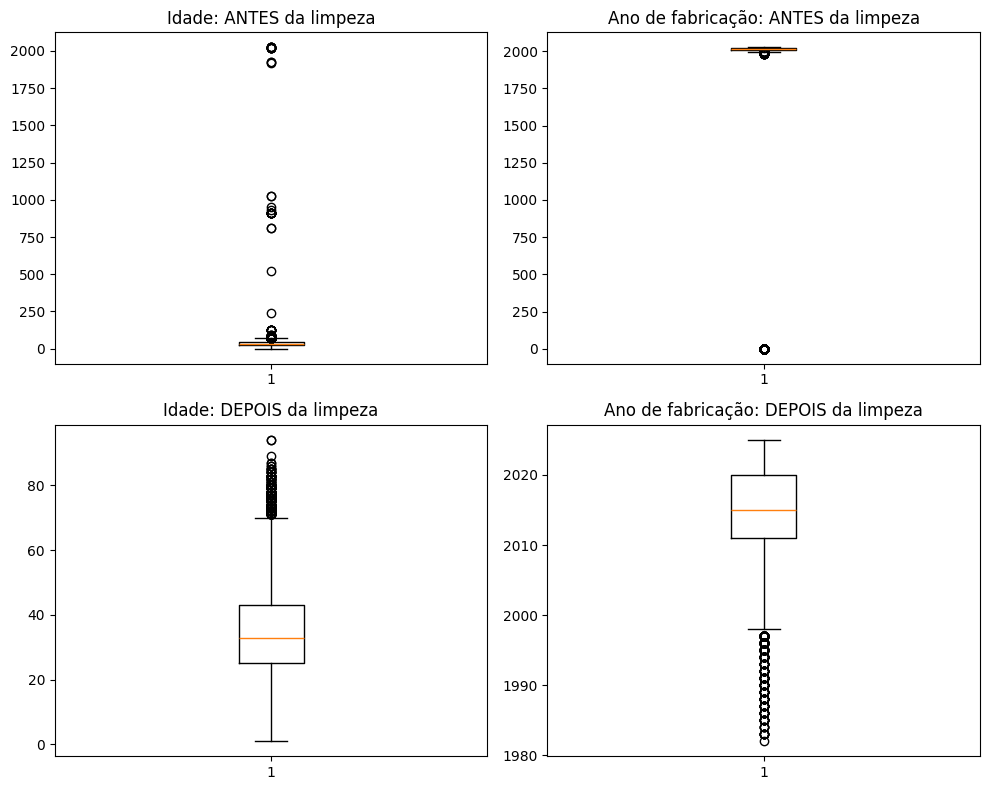

,variável,momento,mínimo,mediana,máximo,vazios
0,idade,antes,0.0,32.0,2023.0,0
1,idade,depois,1.0,33.0,94.0,1672
2,ano_fabricacao_veiculo,antes,0.0,2014.0,2025.0,0
3,ano_fabricacao_veiculo,depois,1982.0,2015.0,2025.0,4842


In [88]:
antes = df.loc[base.index]

fig, ax = plt.subplots(2, 2, figsize=(10, 8))

ax[0, 0].boxplot(pd.to_numeric(antes["idade"], errors="coerce").dropna())
ax[0, 0].set_title("Idade: ANTES da limpeza")
ax[0, 1].boxplot(pd.to_numeric(antes["ano_fabricacao_veiculo"], errors="coerce").dropna())
ax[0, 1].set_title("Ano de fabricação: ANTES da limpeza")

ax[1, 0].boxplot(base["idade"].dropna())
ax[1, 0].set_title("Idade: DEPOIS da limpeza")
ax[1, 1].boxplot(base["ano_fabricacao_veiculo"].dropna())
ax[1, 1].set_title("Ano de fabricação: DEPOIS da limpeza")

plt.tight_layout()
plt.show()

# resumo em números
resumo = []
for c in ["idade", "ano_fabricacao_veiculo"]:
    for momento, serie in [("antes", pd.to_numeric(antes[c], errors="coerce")), ("depois", base[c])]:
        resumo.append({"variável": c, "momento": momento, "mínimo": serie.min(),
                       "mediana": serie.median(), "máximo": serie.max(), "vazios": serie.isna().sum()})
pd.DataFrame(resumo)

**O que a limpeza mudou:**
* **Idade:** antes ia de 0 a 2023; depois, de 1 a 94 anos. A mediana praticamente não mudou (32 → 33 anos).
* **Ano de fabricação:** antes ia de 0 a 2025; depois, de 1982 a 2025. A mediana também quase não mudou (2014 → 2015).
* Os valores impossíveis viraram vazio: 1.672 idades (3,5%) e 4.842 anos de fabricação (10,0%). Esses vazios serão preenchidos com a mediana na modelagem.
* Mantive os outliers **plausíveis** (idades avançadas, motos antigas), porque são casos reais.

Como a mediana quase não mudou, a limpeza tirou erros sem distorcer os dados.

## 4. Exploração

### Teste Qui-Quadrado

Para saber se a letalidade muda de verdade entre grupos, uso o **qui-quadrado** (p-valor menor que 0,05 = diferença provavelmente não é acaso) e o **V de Cramér**, que mostra se a diferença é **fraca (\~0,1), moderada (\~0,3) ou forte (~0,5)**.

In [89]:
def testar(coluna): # monta a tabela cruzada (grupo × morte), roda o qui-quadrado e calcula o V de Cramér
    tabela = pd.crosstab(base[coluna], base["morte"])
    chi2, p, _, _ = chi2_contingency(tabela)
    v = np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))
    print(f"{coluna}: p-valor = {p:.3g} | V de Cramér = {v:.2f}")

def grafico(coluna, titulo): # calcula a letalidade de cada grupo (a média da coluna `morte`, vezes 100) e desenha um gráfico de barras
    letalidade = base.groupby(coluna)["morte"].mean().mul(100).sort_values()
    letalidade.plot.barh(figsize=(7, 0.35 * len(letalidade) + 1))
    plt.title(titulo)
    plt.xlabel("% de motociclistas acidentados que morreram")
    plt.ylabel("")
    plt.show()

### H1: o tipo de acidente é o fator mais associado à morte

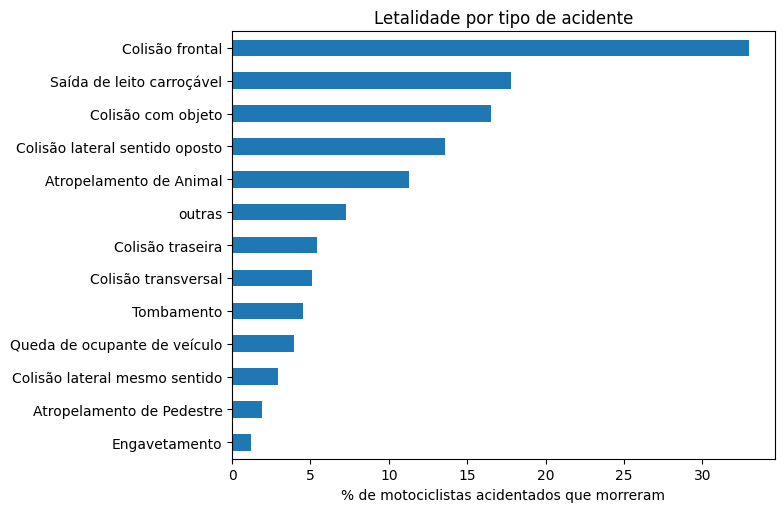

tipo_acidente_grupo: p-valor = 0 | V de Cramér = 0.31


In [90]:
grafico("tipo_acidente_grupo", "Letalidade por tipo de acidente")
testar("tipo_acidente_grupo")

* **Efeito moderado:** V de Cramér = 0,31

Na colisão frontal, cerca de 1 em cada 3 motociclistas morre (\~33%). Em seguida vêm saída de pista (\~18%) e colisão com objeto (\~16%). Na queda, a letalidade é de ~4%.

In [91]:
# H1: comparo o tipo de acidente com todas as outras variáveis
# calculo o V de Cramér de todas as variáveis categóricas e coloco em ordem

variaveis = ["tipo_acidente_grupo", "causa_acidente_grupo", "fase_dia", "uf", "uso_solo",
             "tipo_pista", "tracado_via", "condicao_metereologica", "faixa_etaria",
             "sexo", "tipo_envolvido", "fim_de_semana", "outro_veiculo"]

resultado = []
for coluna in variaveis:
    tabela = pd.crosstab(base[coluna], base["morte"])
    chi2, p, _, _ = chi2_contingency(tabela)
    v = np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))
    resultado.append((coluna, round(v, 2), p))

ranking = pd.DataFrame(resultado, columns=["variável", "V de Cramér", "p-valor"])
print(ranking.sort_values("V de Cramér", ascending=False).to_string(index=False))

              variável  V de Cramér       p-valor
   tipo_acidente_grupo         0.31  0.000000e+00
  causa_acidente_grupo         0.25  0.000000e+00
              uso_solo         0.18  0.000000e+00
            tipo_pista         0.17 4.126033e-308
              fase_dia         0.14 2.771422e-209
                    uf         0.12 2.051421e-145
           tracado_via         0.08  5.068188e-56
          faixa_etaria         0.08  2.292135e-64
         fim_de_semana         0.08  1.712630e-76
                  sexo         0.07  1.116572e-51
condicao_metereologica         0.06  4.825394e-32
        tipo_envolvido         0.06  3.778516e-41
         outro_veiculo         0.03  3.945931e-10


Entre as 13 variáveis, o tipo de acidente tem a maior associação com a morte (V = 0,31), seguido da causa (0,25), do uso do solo (0,18) e do tipo de pista (0,17). **H1 se confirma.**

### H2: acidentes à noite e no amanhecer são mais letais que os de dia

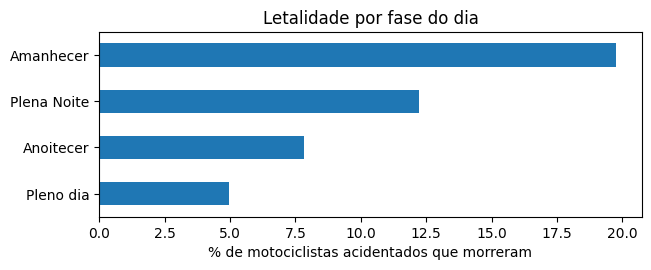

fase_dia: p-valor = 2.77e-209 | V de Cramér = 0.14


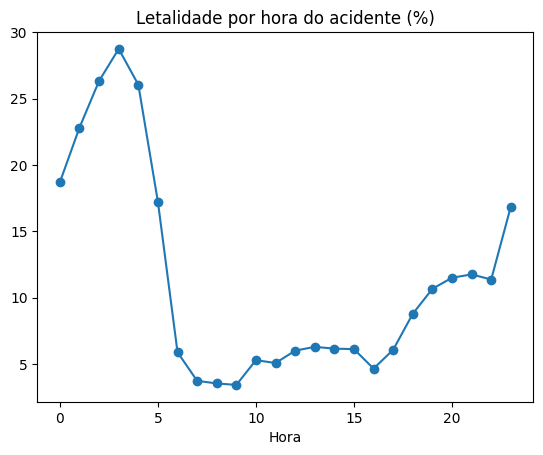

In [92]:
grafico("fase_dia", "Letalidade por fase do dia")
testar("fase_dia")

base.groupby("hora")["morte"].mean().mul(100).plot(marker="o")
plt.title("Letalidade por hora do acidente (%)")
plt.xlabel("Hora")
plt.show()

* **Efeito fraco a moderado:** V de Cramér = 0,14

O pior momento é o amanhecer (\~20%), ainda pior que a noite plena (~12%). A letalidade chega a ~29% às 3h da manhã, contra ~3,5% às 7–9h. A curva basicamente tem um formato de U: cai pela manhã, fica baixa durante o dia e sobe novamente a partir de umas 17h mais ou menos. H2 se confirma.

### Complemento H2: Perfil que vai mais a óbito

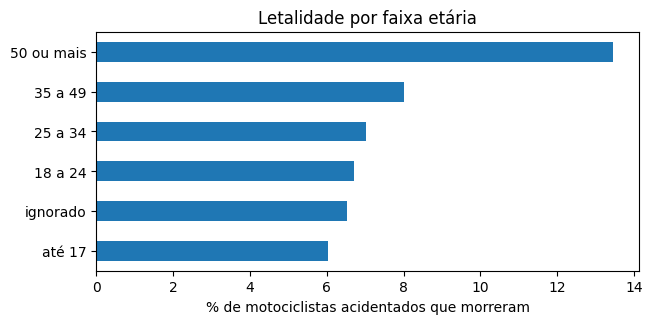

faixa_etaria: p-valor = 2.29e-64 | V de Cramér = 0.08
sexo: p-valor = 1.12e-51 | V de Cramér = 0.07
tipo_envolvido: p-valor = 3.78e-41 | V de Cramér = 0.06


In [93]:
grafico("faixa_etaria", "Letalidade por faixa etária")
testar("faixa_etaria")
testar("sexo")
testar("tipo_envolvido")

Motociclistas com 50 anos ou mais têm letalidade de 13,5%, contra 6,0% a 8,0% nas outras faixas. Sexo e condutor/garupa têm efeito fraco (0,07 e 0,06 - V de Cramér).

### H3: a diferença entre os estados muda quando se considera o tipo de acidente, o horário e a via

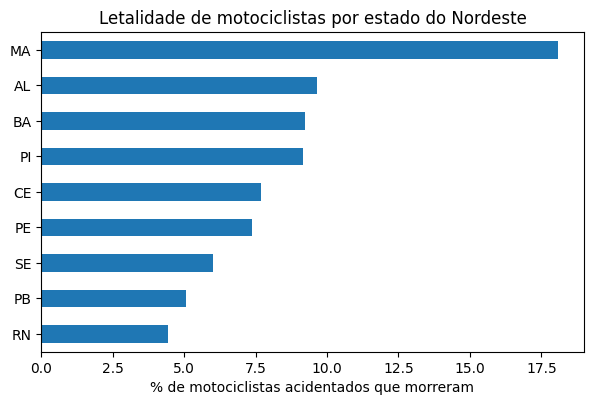

uf: p-valor = 2.05e-145 | V de Cramér = 0.12


In [94]:
grafico("uf", "Letalidade de motociclistas por estado do Nordeste")
testar("uf")

* **Efeito fraco a moderado:** V de Cramér = 0,12.

Na comparação bruta, o Maranhão é o estado mais letal (\~18%), seguido de **Alagoas (\~9,6%)**, Bahia e Piauí (\~9%). Rio Grande do Norte (\~4,4%) e Paraíba (\~5%) têm as menores letalidades.

Essa comparação é **bruta**: um estado com mais acidentes de madrugada ou mais colisões frontais parece mais letal mesmo que o estado em si não acrescente risco. A H3 só pode ser respondida depois do ajuste, na seção de modelos.

## 5. Modelos

O modelo estima a **chance de um motociclista acidentado morrer**, a partir das características da pessoa, do local, do horário e do tipo de acidente.

Comparo dois modelos:
- **Regressão logística:** o mais simples e interpretável.
- **Random Forest:** várias árvores de decisão que "votam" no final.

* Como há poucas mortes, `class_weight = balanced` para o modelo não aprender só a dizer que não há morte.

* Um motociclista e o garupa têm os mesmos dados do acidente. Se um ficar no treino e o outro no teste, o modelo “reconhece” o acidente (vazamento). Por isso uso o StratifiedGroupKFold: as pessoas do mesmo acidente ficam sempre na mesma parte, e cada parte tem a mesma proporção de mortes.

In [95]:
entradas_num = ["idade", "idade_moto", "hora"]
entradas_cat = ["sexo", "tipo_envolvido", "uf", "fase_dia", "fim_de_semana", "condicao_metereologica",
                "tipo_pista", "tracado_via", "uso_solo", "tipo_acidente_grupo", "causa_acidente_grupo",
                "outro_veiculo"]

X = base[entradas_num + entradas_cat]
y = base["morte"]
grupos = base["id"]  # código do acidente

preparo = ColumnTransformer([
    ("num", Pipeline([("vazios", SimpleImputer(strategy="median")),
                      ("escala", StandardScaler())]), entradas_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), entradas_cat),
])

modelos = {
    "Regressão logística": Pipeline([
        ("preparo", preparo),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ]),
    "Random Forest": Pipeline([
        ("preparo", preparo),
        ("modelo", RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                          class_weight="balanced_subsample",
                                          random_state=SEED, n_jobs=-1)),
    ]),
}
print("variáveis de entrada:", len(entradas_num + entradas_cat))

variáveis de entrada: 15


### Validação Cruzada e métricas

Divido os acidentes em 5 partes. O modelo treina em 4 e é testado na que ficou de fora, cinco vezes. A nota final é a média das 5 rodadas.

* **AUC:** o modelo separa quem morreu de quem sobreviveu? (0,5 = chute; 1 = perfeito)
* **PR-AUC:** foca em acertar os casos de morte. Com classe rara, é mais honesta que a AUC. O chute daria a própria letalidade (0,081).
* **Revocação (Recall):** de todos que morreram, quantos o modelo apontou como alto risco.
* **Precisão:** dos que o modelo apontou como alto risco, quantos de fato morreram.
* **F1:** equilíbrio entre revocação e precisão.

In [96]:
kfold = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas = {"AUC": "roc_auc", "PR-AUC": "average_precision",
            "Revocação": "recall", "Precisão": "precision", "F1": "f1"}

resultados = {}
for nome, modelo in modelos.items():
    notas = cross_validate(modelo, X, y, groups=grupos, cv=kfold, scoring=metricas)
    resultados[nome] = {m: notas["test_" + m].mean() for m in metricas}
    print(nome, "avaliado")

print(f"\nreferência (chute) para a PR-AUC: {y.mean():.3f}")
pd.DataFrame(resultados).T.round(3)

Regressão logística avaliado
Random Forest avaliado

referência (chute) para a PR-AUC: 0.081


,AUC,PR-AUC,Revocação,Precisão,F1
Regressão logística,0.838,0.375,0.751,0.228,0.350
Random Forest,0.840,0.384,0.679,0.262,0.378


**Resultados:**
* Os dois modelos tiveram desempenho praticamente igual: **AUC de 0,84** e **PR-AUC de ~0,38**, cerca de **4,6 vezes** (regressão logística) e **4,7 vezes** (Random Forest) acima do chute (0,081).
* A regressão logística teve **recall maior (0,75)**: encontra 3 de cada 4 casos de morte. O Random Forest teve precisão um pouco maior (0,26 contra 0,23).
* A precisão é baixa porque a morte é rara: para encontrar a maioria dos casos graves, o modelo também aponta muitos que sobreviveram. Para fiscalização preventiva, isso é aceitável, porque deixar de apontar uma situação de risco custa mais do que um alerta a mais.
* **Escolha: Regressão logística:** mesmo desempenho, mais simples, mais fácil de interpretar e com maior revocação.

In [97]:
# validação temporal: treino nos anos mais antigos e testo nos mais recentes
# a validação cruzada mistura os anos; aqui vejo se o modelo continua bom em anos que ele não viu
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score, f1_score

treino = base["ano"] <= 2023   # 2021, 2022 e 2023
teste = base["ano"] >= 2024    # 2024 e 2025

print(f"treino: {treino.sum()} pessoas ({y[treino].sum()} mortes) | teste: {teste.sum()} pessoas ({y[teste].sum()} mortes)")
print(f"letalidade no treino: {y[treino].mean():.3f} | no teste: {y[teste].mean():.3f} (= PR-AUC do chute no teste)")

resultados_tempo = {}
for nome, modelo in modelos.items():
    m = clone(modelo)                      # cópia nova, para não mexer nos modelos de cima
    m.fit(X[treino], y[treino])
    prob = m.predict_proba(X[teste])[:, 1]  # chance de morte estimada
    prev = m.predict(X[teste])              # 1 = apontado como risco (limiar 0,5)
    resultados_tempo[nome] = {
        "AUC": roc_auc_score(y[teste], prob),
        "PR-AUC": average_precision_score(y[teste], prob),
        "Revocação": recall_score(y[teste], prev),
        "Precisão": precision_score(y[teste], prev),
        "F1": f1_score(y[teste], prev),
    }

# coloco lado a lado: validação cruzada (de cima) e validação temporal
comparacao = pd.concat({"validação cruzada": pd.DataFrame(resultados).T,
                        "temporal (2021–23 → 2024–25)": pd.DataFrame(resultados_tempo).T}, axis=1)
comparacao.round(3).T

treino: 25484 pessoas (2153 mortes) | teste: 22725 pessoas (1742 mortes)
letalidade no treino: 0.084 | no teste: 0.077 (= PR-AUC do chute no teste)


Regressão logística  Random Forest
validação cruzada            AUC                      0.838          0.840
                             PR-AUC                   0.375          0.384
                             Revocação                0.751          0.679
                             Precisão                 0.228          0.262
                             F1                       0.350          0.378
temporal (2021–23 → 2024–25) AUC                      0.841          0.842
                             PR-AUC                   0.382          0.383
                             Revocação                0.745          0.662
                             Precisão                 0.228          0.262
                             F1                       0.349          0.375

**Resultado da validação temporal:**
* Treinando com 2021–2023 (25.484 pessoas, 2.153 mortes) e testando em 2024–2025 (22.725 pessoas, 1.742 mortes), as métricas praticamente não mudam: AUC de 0,84 e PR-AUC de 0,382 e 0,383 nos modelos, contra 0,077 do chute (a letalidade de 2024–2025).
* A regressão logística continua encontrando mais mortes (revocação de 0,745 contra 0,662 da Random Forest).
* Ou seja, o desempenho não depende de misturar os anos: o modelo se mantém em anos que não viu.

In [98]:
preparo_or = ColumnTransformer([
    ("num", Pipeline([("vazios", SimpleImputer(strategy="median")),
                      ("escala", StandardScaler())]), entradas_num),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), entradas_cat),
])
logistica = Pipeline([("preparo", preparo_or),
                      ("modelo", LogisticRegression(C=1e6, max_iter=5000))])
logistica.fit(X, y)

nomes = logistica.named_steps["preparo"].get_feature_names_out()
coef = logistica.named_steps["modelo"].coef_[0]
razao_chances = pd.Series(np.exp(coef), index=nomes).round(2)
razao_chances.index = razao_chances.index.str.replace("num__", "").str.replace("cat__", "")

print("10 características que MAIS aumentam a chance de morte:\n")
print(razao_chances.sort_values(ascending=False).head(10).to_string())
print("\nEstados em relação a Alagoas (OR > 1 = mais letal que AL):")
print(razao_chances[razao_chances.index.str.startswith("uf_")].sort_values().to_string())

10 características que MAIS aumentam a chance de morte:

causa_acidente_grupo_Velocidade Incompatível           2.82
tipo_acidente_grupo_Colisão com objeto                 2.67
causa_acidente_grupo_Transitar na contramão            2.61
uf_MA                                                  2.58
outro_veiculo_sim                                      2.32
tipo_acidente_grupo_Saída de leito carroçável          2.27
causa_acidente_grupo_Ultrapassagem Indevida            2.17
causa_acidente_grupo_Ausência de reação do condutor    1.78
tipo_pista_Simples                                     1.77
tipo_acidente_grupo_Colisão frontal                    1.73

Estados em relação a Alagoas (OR > 1 = mais letal que AL):
uf_RN    0.77
uf_PB    0.94
uf_SE    0.94
uf_BA    1.19
uf_PI    1.30
uf_CE    1.39
uf_PE    1.46
uf_MA    2.58


com `drop="first"`, a categoria de referência de cada variável é a primeira em ordem alfabética. Para os estados funciona (a referência é AL). Mas, para o tipo de acidente, a referência virou "Atropelamento de Animal", que já é um acidente bem letal (~11%). Por isso a colisão frontal aparece com OR de 1,73. Na célula abaixo refaço a análise com **referências escolhidas por mim** e com **intervalo de confiança de 95% e p-valor**. São esses os números que vou usar no relatório.

In [99]:
# razões de chances com intervalo de confiança de 95% e p-valor (biblioteca statsmodels)
import statsmodels.formula.api as smf

dados_or = base.copy()
# idade em blocos de 10 anos e idade da moto em blocos de 5 anos (vazios = mediana)
dados_or["idade_10anos"] = dados_or["idade"].fillna(dados_or["idade"].median()) / 10
dados_or["idade_moto_5anos"] = dados_or["idade_moto"].fillna(dados_or["idade_moto"].median()) / 5

def referencia(coluna, preferida=None):
    # uso a categoria que eu escolhi; se não existir, a mais comum
    if preferida is not None and preferida in set(dados_or[coluna]):
        return preferida
    return dados_or[coluna].value_counts().index[0]

referencias = {
    "uf": referencia("uf", "AL"),
    "tipo_acidente_grupo": referencia("tipo_acidente_grupo", "Queda de ocupante de veículo"),
    "causa_acidente_grupo": referencia("causa_acidente_grupo"),
    "fase_dia": referencia("fase_dia", "Pleno dia"),
    "sexo": referencia("sexo", "Feminino"),
    "tipo_envolvido": referencia("tipo_envolvido", "Condutor"),
    "fim_de_semana": referencia("fim_de_semana", "não"),
    "condicao_metereologica": referencia("condicao_metereologica"),
    "tipo_pista": referencia("tipo_pista", "Dupla"),
    "tracado_via": referencia("tracado_via", "Reta"),
    "uso_solo": referencia("uso_solo"),
    "outro_veiculo": referencia("outro_veiculo", "não"),
}
print("Categorias de referência:")
for coluna, ref in referencias.items():
    print(f"  {coluna}: {ref}")

termos = " + ".join(f"C({c}, Treatment(reference={r!r}))" for c, r in referencias.items())
modelo_or = smf.logit(f"morte ~ idade_10anos + idade_moto_5anos + {termos}", data=dados_or).fit(
    disp=False, maxiter=200,
    cov_type="cluster", cov_kwds={"groups": dados_or["id"]})  # erro-padrão agrupado por acidente

print("o modelo convergiu?", modelo_or.mle_retvals["converged"])

ic = modelo_or.conf_int()
tabela_or = pd.DataFrame({
    "OR": np.exp(modelo_or.params),
    "IC95% inferior": np.exp(ic[0]),
    "IC95% superior": np.exp(ic[1]),
    "p-valor": modelo_or.pvalues,
}).drop("Intercept").round(3)

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
tabela_or

Categorias de referência:
  uf: AL
  tipo_acidente_grupo: Queda de ocupante de veículo
  causa_acidente_grupo: outras
  fase_dia: Pleno dia
  sexo: Feminino
  tipo_envolvido: Condutor
  fim_de_semana: não
  condicao_metereologica: Céu Claro
  tipo_pista: Dupla
  tracado_via: Reta
  uso_solo: Sim
  outro_veiculo: não
o modelo convergiu? True


,OR,IC95% inferior,IC95% superior,p-valor
"C(uf, Treatment(reference='AL'))[T.BA]",1.121,0.916,1.372,0.268
"C(uf, Treatment(reference='AL'))[T.CE]",1.332,1.068,1.660,0.011
"C(uf, Treatment(reference='AL'))[T.MA]",2.455,1.978,3.047,0.000
"C(uf, Treatment(reference='AL'))[T.PB]",0.895,0.713,1.123,0.338
"C(uf, Treatment(reference='AL'))[T.PE]",1.388,1.129,1.707,0.002
"C(uf, Treatment(reference='AL'))[T.PI]",1.231,0.987,1.537,0.065
"C(uf, Treatment(reference='AL'))[T.RN]",0.729,0.577,0.919,0.008
"C(uf, Treatment(reference='AL'))[T.SE]",0.889,0.660,1.197,0.438
"C(tipo_acidente_grupo, Treatment(reference='Queda de ocupante de veículo'))[T.Atropelamento de Animal]",2.022,1.328,3.081,0.001
"C(tipo_acidente_grupo, Treatment(reference='Queda de ocupante de veículo'))[T.Atropelamento de Pedestre]",0.270,0.170,0.430,0.000


Refazendo a regressão logística com a biblioteca `statsmodels`, que calcula para cada fator a **razão de chances (OR)**, o **intervalo de confiança de 95%** e o **p-valor**. Escolhi referências fáceis de ler: **Alagoas** (estados), **queda** (tipo de acidente), **pleno dia** (horário), **mulher**, **condutor**, **pista dupla**, **reta** e **trecho urbano**. Para a causa do acidente, a referência é "outras".

* OR = 2 → o dobro da chance de morrer em relação à referência; OR = 0,5 → metade.
* Como o condutor e o garupa do mesmo acidente não são independentes, o intervalo de confiança e o p-valor usam **erro-padrão agrupado por acidente** (`cov_type="cluster"`). Isso não muda as ORs, só deixa os intervalos um pouco mais largos (mais honestos).
* O resultado é estatisticamente significativo quando o intervalo de confiança **não inclui o 1** (p-valor < 0,05).
* Idade: OR para cada 10 anos a mais. Idade da moto: para cada 5 anos a mais.
* Causas (em relação a “outras”): velocidade incompatível (2,37), transitar na contramão (2,22), ultrapassagem indevida (1,81) e ausência de reação do condutor (1,52). Chuva também aumenta a chance de morte (1,38 em relação a céu claro). Ingestão de álcool não teve efeito significativo (1,05; o intervalo inclui o 1).

In [100]:
# deixando os nomes da tabela mais curtos pra conseguir ler
tabela_or.index = tabela_or.index.str.replace(r"C\((\w+), Treatment\(reference=.*?\)\)\[T\.", r"\1 = ", regex=True).str.replace("]", "")
print(tabela_or.to_string())

                                                                                     OR  IC95% inferior  IC95% superior  p-valor
uf = BA                                                                           1.121           0.916           1.372    0.268
uf = CE                                                                           1.332           1.068           1.660    0.011
uf = MA                                                                           2.455           1.978           3.047    0.000
uf = PB                                                                           0.895           0.713           1.123    0.338
uf = PE                                                                           1.388           1.129           1.707    0.002
uf = PI                                                                           1.231           0.987           1.537    0.065
uf = RN                                                                           0.729          

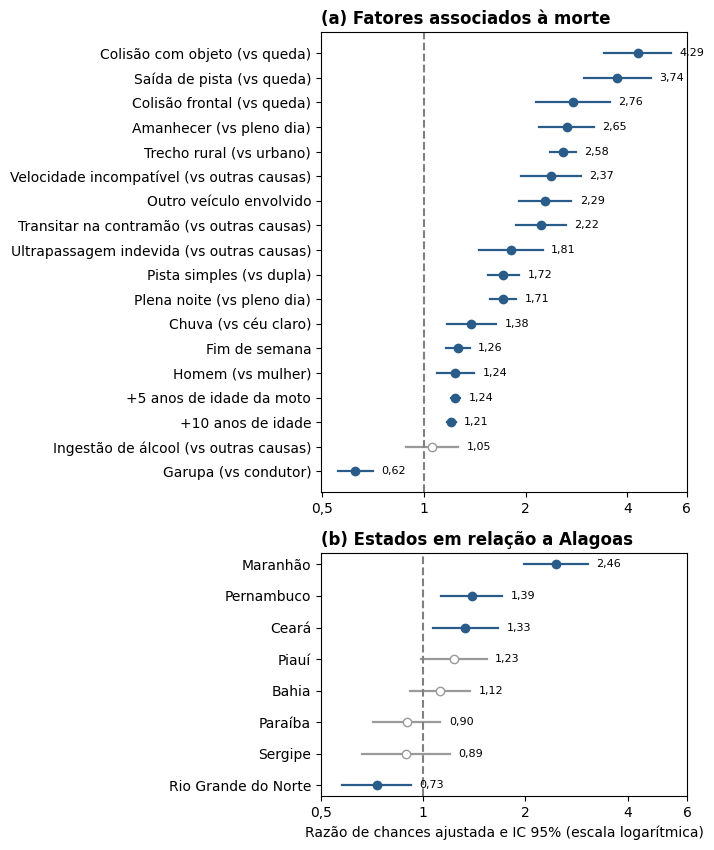

In [101]:
# Figura 5: gráfico das razões de chances (OR) com intervalo de confiança
# cada ponto é a OR; a linha é o intervalo de 95%; a linha tracejada no 1 = "sem diferença"

# 1) escolho as linhas da tabela que quero mostrar (texto que procuro -> nome no gráfico)
fatores = {
    "Colisão com objeto": "Colisão com objeto (vs queda)",
    "Saída de leito": "Saída de pista (vs queda)",
    "Colisão frontal": "Colisão frontal (vs queda)",
    "Amanhecer": "Amanhecer (vs pleno dia)",
    "uso_solo = Não": "Trecho rural (vs urbano)",
    "Velocidade": "Velocidade incompatível (vs outras causas)",
    "outro_veiculo = sim": "Outro veículo envolvido",
    "contramão": "Transitar na contramão (vs outras causas)",
    "Ultrapassagem": "Ultrapassagem indevida (vs outras causas)",
    "tipo_pista = Simples": "Pista simples (vs dupla)",
    "Plena Noite": "Plena noite (vs pleno dia)",
    "= Chuva": "Chuva (vs céu claro)",
    "fim_de_semana = sim": "Fim de semana",
    "sexo = Masculino": "Homem (vs mulher)",
    "idade_moto_5anos": "+5 anos de idade da moto",
    "idade_10anos": "+10 anos de idade",
    "lcool": "Ingestão de álcool (vs outras causas)",
    "Passageiro": "Garupa (vs condutor)",
}
estados = {"uf = MA": "Maranhão", "uf = PE": "Pernambuco", "uf = CE": "Ceará", "uf = PI": "Piauí",
           "uf = BA": "Bahia", "uf = PB": "Paraíba", "uf = SE": "Sergipe", "uf = RN": "Rio Grande do Norte"}

def pegar_linhas(escolhidos):
    # procuro cada texto no nome das linhas da tabela e guardo OR e intervalo
    linhas = []
    for texto, nome in escolhidos.items():
        achou = tabela_or[tabela_or.index.str.contains(texto, regex=False)]
        if len(achou) == 0:
            print("não achei:", texto)  # se aparecer isso, confiro o nome na tabela
            continue
        linha = achou.iloc[0]
        linhas.append((nome, linha["OR"], linha["IC95% inferior"], linha["IC95% superior"]))
    return linhas

def desenhar(ax, linhas, titulo):
    n = len(linhas)
    for i, (nome, oddsratio, inf, sup) in enumerate(linhas):
        y = n - 1 - i                       # o primeiro da lista fica em cima
        significativo = inf > 1 or sup < 1  # o intervalo não cruza o 1
        cor = "#2a5c8a" if significativo else "#9a9a9a"
        ax.plot([inf, sup], [y, y], color=cor, lw=1.6)
        ax.plot(oddsratio, y, "o", color=cor, mfc=cor if significativo else "white")
        ax.text(sup * 1.06, y, f"{oddsratio:.2f}".replace(".", ","), va="center", fontsize=8)
    ax.axvline(1, color="gray", ls="--")    # OR = 1 é "sem diferença"
    ax.set_yticks(range(n))
    ax.set_yticklabels([l[0] for l in linhas][::-1])
    ax.set_xscale("log")                    # escala log: 2x e 0,5x ficam à mesma distância do 1
    ax.set_xticks([0.5, 1, 2, 4, 6])
    ax.set_xticklabels(["0,5", "1", "2", "4", "6"])
    ax.minorticks_off()
    ax.set_title(titulo, loc="left", fontweight="bold")

# 2) desenho os dois painéis: fatores em cima, estados embaixo
fig, ax = plt.subplots(2, 1, figsize=(7.2, 8.6), gridspec_kw={"height_ratios": [18, 9.5]})
desenhar(ax[0], pegar_linhas(fatores), "(a) Fatores associados à morte")
desenhar(ax[1], pegar_linhas(estados), "(b) Estados em relação a Alagoas")
ax[1].set_xlabel("Razão de chances ajustada e IC 95% (escala logarítmica)")
plt.tight_layout()
plt.savefig("razao_chances.png", dpi=200)  # salvo para usar no relatório
plt.show()

O gráfico mostra a tabela acima. **Ponto cheio:** o intervalo não cruza o 1, efeito significativo. **Ponto vazio:** o intervalo inclui o 1, sem diferença (álcool; BA, PB, SE e PI em relação a AL). Em (b), Alagoas fica no meio do grupo e o Maranhão fica sozinho no alto: **H3 se confirma** (a ordem dos estados muda depois do ajuste).

**Leitura dos resultados:**
* **Tipo de acidente (em relação à queda):** colisão com objeto (OR 4,29), saída de pista (3,74) e colisão frontal (2,76) são os mais letais.
* **Local e via:** trecho rural (2,58 em relação ao urbano), pista simples (1,72 em relação à dupla) e outro veículo envolvido (2,29).
* **Horário (em relação ao pleno dia):** amanhecer (2,65) e plena noite (1,71). Fim de semana: 1,26.
* **Pessoa:** homem 1,24 (em relação à mulher); garupa 0,62 (morre menos que o condutor); cada 10 anos de idade, 1,21; cada 5 anos de idade da moto, 1,24.
* **Estados (em relação a Alagoas):** MA (2,46), PE (1,39) e CE (1,33) são mais letais; BA, PB, SE e PI não diferem de Alagoas (o intervalo inclui o 1); RN é menos letal (0,73).
* **Piauí:** o intervalo inclui o 1 (0,99 a 1,54; p = 0,065), por isso não afirmo diferença em relação a Alagoas.

### Números complementares

In [102]:
from scipy.stats import mannwhitneyu
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

# 1) estatística descritiva das variáveis numéricas
print("=== DESCRITIVA ===")
print(base[["idade", "idade_moto", "hora"]].describe().round(1))

# 2) idade, idade da moto e hora: comparo quem morreu com quem sobreviveu (média e mediana)
print("\n=== POR GRUPO (0 = sobreviveu, 1 = morreu) ===")
print(base.groupby("morte")[["idade", "idade_moto", "hora"]].agg(["mean", "median"]).round(1))

# 3) teste de Mann-Whitney: a idade de quem morreu é diferente da de quem sobreviveu?
for coluna in ["idade", "idade_moto"]:
    morreu = base.loc[base["morte"] == 1, coluna].dropna()
    sobreviveu = base.loc[base["morte"] == 0, coluna].dropna()
    estat, p = mannwhitneyu(morreu, sobreviveu)
    print(f"\nMann-Whitney {coluna}: p-valor = {p:.2e}")

# 4) correlação de Spearman entre as variáveis numéricas e a morte
print("\n=== CORRELAÇÃO (Spearman) ===")
print(base[["idade", "idade_moto", "hora", "morte"]].corr(method="spearman").round(2))

# 5) matriz de confusão da regressão logística, com a mesma validação cruzada agrupada
previsto = cross_val_predict(modelos["Regressão logística"], X, y, groups=grupos, cv=kfold)
print("\n=== MATRIZ DE CONFUSÃO (linhas = real, colunas = previsto) ===")
print(confusion_matrix(y, previsto))

# 6) que parte das mortes acontece entre 0h e 6h, e que parte dos acidentes
madrugada = base["hora"].between(0, 5)
print(f"\nmortes entre 0h e 6h: {base.loc[madrugada, 'morte'].sum()} de {base['morte'].sum()} "
      f"({base.loc[madrugada, 'morte'].sum() / base['morte'].sum():.1%})")
print(f"acidentados entre 0h e 6h: {madrugada.mean():.1%}")

=== DESCRITIVA ===
         idade  idade_moto     hora
count  46537.0     43367.0  48209.0
mean      35.0         8.3     13.5
std       12.6         6.2      5.7
min        1.0         0.0      0.0
25%       25.0         3.0      8.0
50%       33.0         8.0     15.0
75%       43.0        12.0     18.0
max       94.0        42.0     23.0

=== POR GRUPO (0 = sobreviveu, 1 = morreu) ===
      idade        idade_moto         hora       
       mean median       mean median  mean median
morte                                            
0      34.7   33.0        8.0    8.0  13.5   14.0
1      38.3   37.0       11.2   11.0  13.5   16.0

Mann-Whitney idade: p-valor = 3.94e-46

Mann-Whitney idade_moto: p-valor = 5.75e-161

=== CORRELAÇÃO (Spearman) ===
            idade  idade_moto  hora  morte
idade        1.00        0.14 -0.03   0.07
idade_moto   0.14        1.00  0.06   0.13
hora        -0.03        0.06  1.00   0.02
morte        0.07        0.13  0.02   1.00

=== MATRIZ DE CONFUSÃO (li

**Resultado:**
* **Idade e idade da moto:** quem morreu era mais velho (mediana de 37 contra 33 anos) e estava em motos mais antigas (11 contra 8 anos). As duas diferenças são significativas pelo teste de Mann-Whitney (que não exige distribuição normal).
* **Correlação de Spearman:** fraca entre as variáveis e a morte (no máximo 0,13) e entre elas (no máximo 0,14), então não há redundância entre as entradas. A hora tem correlação quase zero (0,02) porque a relação é em **U**: a correlação só mede relações que sempre sobem ou sempre descem.
* **Matriz de confusão:** das 3.895 mortes, o modelo apontou 2.927 e deixou passar 968, com 9.905 alarmes falsos. Ele marca 26,6% dos acidentados e, nesse grupo, estão 3 de cada 4 mortes.
* **Madrugada:** entre 0h e 6h estão 7,1% dos acidentados, mas 19,4% das mortes.

In [103]:
# Números que aparecem na apresentação e no relatório: calculo todos aqui

# 1) letalidade (%) por grupo, com quantas pessoas e quantas mortes
for coluna in ["tipo_acidente_grupo", "fase_dia", "uf", "faixa_etaria", "hora"]:
    tabela = base.groupby(coluna)["morte"].agg(pessoas="count", mortes="sum", letalidade="mean")
    tabela["letalidade"] = (tabela["letalidade"] * 100).round(1)
    print(f"\n=== Letalidade por {coluna} ===")
    print(tabela.sort_values("letalidade", ascending=False).to_string())

# 2) letalidade cruzando trecho (uso_solo: Sim = urbano, Não = rural) e tipo de pista
print("\n=== Letalidade (%) por uso do solo x tipo de pista ===")
print(base.pivot_table(index="uso_solo", columns="tipo_pista", values="morte", aggfunc="mean").mul(100).round(1))

# 3) números que saem da matriz de confusão da regressão logística
vn, fp, fn, vp = confusion_matrix(y, previsto).ravel()
total = vn + fp + fn + vp
print("\n=== Matriz de confusão em números ===")
print(f"acurácia do modelo: {(vn + vp) / total:.1%}")
print(f"acurácia de quem diz sempre 'sobrevive': {(vn + fp) / total:.1%}")
print(f"o modelo marca como risco {(vp + fp) / total:.1%} dos acidentados")
print(f"precisão ÷ letalidade: {(vp / (vp + fp)) / y.mean():.1f} vezes")

# 4) quantas vezes a PR-AUC de cada modelo fica acima do acaso
for nome in resultados:
    print(f"{nome}: PR-AUC = {resultados[nome]['PR-AUC'] / y.mean():.1f} vezes o acaso")

# 5) madrugada: mortes por ano e o que seria uma queda de 20%
anos = base["ano"].nunique()
mortes_madrugada = base.loc[madrugada, "morte"].sum()
print(f"\nletalidade entre 0h e 6h: {base.loc[madrugada, 'morte'].mean():.1%}")
print(f"mortes entre 0h e 6h por ano: {mortes_madrugada / anos:.0f}")
print(f"20% dessas mortes: {0.2 * mortes_madrugada / anos:.0f} por ano")

# 6) razão de chances BRUTA do amanhecer contra o pleno dia (para comparar com a ajustada, 2,65)
letal = base.groupby("fase_dia")["morte"].mean()
chance = letal / (1 - letal)
print(f"razão de chances bruta, amanhecer vs pleno dia: {chance['Amanhecer'] / chance['Pleno dia']:.2f}")


=== Letalidade por tipo_acidente_grupo ===
                                pessoas  mortes  letalidade
tipo_acidente_grupo                                        
Colisão frontal                    4054    1336        33.0
Saída de leito carroçável          1403     250        17.8
Colisão com objeto                 1544     255        16.5
Colisão lateral sentido oposto     1015     138        13.6
Atropelamento de Animal            1478     167        11.3
outras                              331      24         7.3
Colisão traseira                  11448     623         5.4
Colisão transversal                9760     499         5.1
Tombamento                         4764     215         4.5
Queda de ocupante de veículo       4189     165         3.9
Colisão lateral mesmo sentido      6599     194         2.9
Atropelamento de Pedestre          1300      25         1.9
Engavetamento                       324       4         1.2

=== Letalidade por fase_dia ===
             pessoas  m

## 6. Insights e Discussão

### Resumo das hipóteses
| Hipótese | Resultado | Evidência |
|---|---|---|
| **H1** Tipo de acidente | Confirmada | Maior V de Cramér entre as 13 variáveis (0,31), à frente da causa (0,25). Colisão frontal: letalidade de 33%, contra 3,9% na queda. Ajustado: colisão com objeto (OR 4,29), saída de pista (3,74) e colisão frontal (2,76) em relação à queda |
| **H2** Horário | Confirmada | Letalidade de 28,7% às 3h contra 3,4% a 3,7% entre 7h e 9h; V = 0,14. Ajustado: amanhecer OR 2,65 e plena noite 1,71 em relação ao pleno dia |
| **H3** Estado | Confirmada | Bruto: MA 18,1%, AL 9,6%, RN 4,4% (V = 0,12). Ajustado: MA, PE e CE mais letais que AL; BA, PB, SE e PI iguais a AL; RN menos letal. A ordem dos estados muda depois do ajuste |

### Insights acionáveis

**Insight 1: a madrugada concentra as mortes**
Percebemos que entre 0h e 6h ocorrem 7,1% dos acidentes de moto, mas 19,4% das mortes (letalidade de 22,1%), e que, mesmo comparando acidentes parecidos, a chance de morte no amanhecer é 2,65 vezes a do pleno dia (IC 95%: 2,20 a 3,19). Isso sugere que o horário pesa por si só e que uma ação concentrada nessa faixa de 6 horas alcança quase 1 em cada 5 mortes. As causas (fiscalização, velocidade, socorro) não estão na base. Por isso, recomendamos operações de controle de velocidade da PRF entre 0h e 6h nos trechos com mais acidentes de moto. A decisão foi sustentada pela letalidade por hora, pelo V de Cramér da fase do dia (0,14) e pela razão de chances ajustada. Após 12 meses, o sucesso pode ser avaliado pela letalidade de motociclistas entre 0h e 6h e acompanhado pelo número de mortes nesse horário. A ação será considerada bem-sucedida se essa letalidade cair 20% sem aumento do número de acidentes. Com 151 mortes por ano nesse horário, isso corresponde a cerca de 30 vidas por ano.

**Insight 2: trechos rurais de pista simples**
Percebemos que em trecho rural de pista simples morrem 19,0% dos motociclistas acidentados, contra 2,8% em trecho urbano de pista dupla. No modelo ajustado, trecho rural (OR 2,58) e pista simples (1,72) aumentam a chance de morte, assim como colisão com objeto (4,29), saída de pista (3,74) e colisão frontal (2,76) em relação à queda. Isso sugere que o tipo de trecho e o tipo de colisão concentram o risco. As causas mais associadas à morte apontam na mesma direção: velocidade incompatível (2,37), contramão (2,22) e ultrapassagem indevida (1,81). Por isso, recomendamos priorizar defensas, separação de pistas, sinalização e fiscalização de ultrapassagem e velocidade nesses trechos. A decisão foi sustentada pelo V de Cramér (tipo de acidente 0,31; uso do solo 0,18; tipo de pista 0,17), pela tabela de letalidade por uso do solo e tipo de pista e pelas razões de chances ajustadas. Após 12 meses das intervenções, o sucesso pode ser avaliado pelo número de mortes de motociclistas nos trechos tratados e acompanhado pela letalidade nesses trechos. A ação será considerada bem-sucedida se as mortes caírem mais nos trechos tratados do que em trechos semelhantes não tratados.

**Insight 3: Alagoas e Maranhão**
Percebemos que Alagoas tem a 2ª maior letalidade bruta do Nordeste (9,6%), mas, em igualdade de condições, não difere de BA, PB, SE e PI, enquanto o Maranhão (18,1% bruto) continua 2,46 vezes mais letal que Alagoas (IC 95%: 1,98 a 3,05). Isso sugere que, em Alagoas, a diferença vem do tipo de acidente, do horário e da via, e não do estado em si, e que no Maranhão há algo que a base não mede (socorro, condição das vias ou registro). Por isso, recomendamos que Alagoas foque nas situações dos insights 1 e 2 e que o Maranhão investigue o tempo de socorro, as condições das rodovias e a cobertura do registro de acidentes leves. A decisão foi sustentada pelo qui-quadrado por estado (V = 0,12), pela letalidade bruta e pelas razões de chances ajustadas, com Alagoas como referência. Após 12 meses, o sucesso pode ser avaliado pela razão de chances ajustada do Maranhão e acompanhado pela sua letalidade bruta. A ação será considerada bem-sucedida se a razão de chances do Maranhão em relação a Alagoas diminuir.

### Limitações
* Os dados cobrem só as **rodovias federais**; acidentes em ruas e estradas estaduais ficam de fora.
* O estado físico é o registrado no local; mortes posteriores no hospital podem não aparecer.
* Não há dados de uso de capacete, velocidade medida, fluxo de veículos ou tempo de socorro.
* Causa e tipo de acidente são registrados pela PRF e podem ter erros de classificação.
* A letalidade depende do registro: se um estado registra menos acidentes leves, a letalidade sobe sem o risco ser maior (pode explicar parte da diferença do Maranhão).
* Os resultados mostram **associação**, não causa.

### Trabalhos futuros
Mapear os trechos críticos (BR e km), cruzar com o Sistema de Informações sobre Mortalidade (SIM) para captar mortes no hospital, incluir rodovias estaduais e dados de fluxo de veículos.

## Extra

**Com animação**

In [104]:
import plotly.express as px

# só as mortes, com coordenadas válidas dentro do Nordeste
mortes = base[base["morte"] == 1].copy()
mortes["latitude"] = pd.to_numeric(mortes["latitude"], errors="coerce")
mortes["longitude"] = pd.to_numeric(mortes["longitude"], errors="coerce")
mortes = mortes[mortes["latitude"].between(-19, 0) & mortes["longitude"].between(-49, -34)]

# cores com sentido: quanto mais escuro/vermelho, mais perigoso o horário
cores = {"Pleno dia": "#f2c14e", "Anoitecer": "#f28e2b", "Plena Noite": "#1f3b73", "Amanhecer": "#d62728"}

fig = px.scatter_geo(
    mortes, lat="latitude", lon="longitude", color="fase_dia",
    color_discrete_map=cores,
    category_orders={"fase_dia": ["Pleno dia", "Anoitecer", "Plena Noite", "Amanhecer"]},
    hover_name="municipio",
    hover_data={"uf": True, "br": True, "km": True, "hora": True, "tipo_acidente_grupo": True,
                "fase_dia": False, "latitude": False, "longitude": False},
    labels={"fase_dia": "Fase do dia", "uf": "Estado", "br": "BR", "km": "km",
            "hora": "Hora", "tipo_acidente_grupo": "Tipo de acidente"},
    height=700,
    animation_frame="ano",
    title=f"Onde morrem os motociclistas nas rodovias federais do Nordeste (2021–2025)"
          f"<br><sup>Cada ponto é uma morte ({len(mortes)} mortes com localização válida)</sup>")

fig.update_geos(fitbounds="locations", resolution=50, projection_type="mercator",
                showcountries=True, countrycolor="gray",
                showsubunits=True, subunitcolor="gray", subunitwidth=1,
                showland=True, landcolor="#f5f5f0",
                showocean=True, oceancolor="#dfeaf2",
                showcoastlines=True, coastlinecolor="gray")
fig.update_traces(marker=dict(size=5, opacity=0.7))
fig.update_layout(legend=dict(title="Fase do dia", orientation="h", y=-0.05),
                  margin=dict(l=0, r=0, t=80, b=0))
fig.show()

**Sem animação**

In [105]:
import plotly.express as px

# só as mortes, com coordenadas válidas dentro do Nordeste
mortes = base[base["morte"] == 1].copy()
mortes["latitude"] = pd.to_numeric(mortes["latitude"], errors="coerce")
mortes["longitude"] = pd.to_numeric(mortes["longitude"], errors="coerce")
mortes = mortes[mortes["latitude"].between(-19, 0) & mortes["longitude"].between(-49, -34)]

# cores com sentido: quanto mais escuro/vermelho, mais perigoso o horário
cores = {"Pleno dia": "#f2c14e", "Anoitecer": "#f28e2b", "Plena Noite": "#1f3b73", "Amanhecer": "#d62728"}

fig = px.scatter_geo(
    mortes, lat="latitude", lon="longitude", color="fase_dia",
    color_discrete_map=cores,
    category_orders={"fase_dia": ["Pleno dia", "Anoitecer", "Plena Noite", "Amanhecer"]},
    hover_name="municipio",
    hover_data={"uf": True, "br": True, "km": True, "hora": True, "tipo_acidente_grupo": True,
                "fase_dia": False, "latitude": False, "longitude": False},
    labels={"fase_dia": "Fase do dia", "uf": "Estado", "br": "BR", "km": "km",
            "hora": "Hora", "tipo_acidente_grupo": "Tipo de acidente"},
    height=700,
    title=f"Onde morrem os motociclistas nas rodovias federais do Nordeste (2021–2025)"
          f"<br><sup>Cada ponto é uma morte ({len(mortes)} mortes com localização válida)</sup>")

fig.update_geos(fitbounds="locations", resolution=50, projection_type="mercator",
                showcountries=True, countrycolor="gray",
                showsubunits=True, subunitcolor="gray", subunitwidth=1,
                showland=True, landcolor="#f5f5f0",
                showocean=True, oceancolor="#dfeaf2",
                showcoastlines=True, coastlinecolor="gray")
fig.update_traces(marker=dict(size=5, opacity=0.7))
fig.update_layout(legend=dict(title="Fase do dia", orientation="h", y=-0.05),
                  margin=dict(l=0, r=0, t=80, b=0))
fig.show()

In [106]:
import ipywidgets as widgets

def painel(estado):
    dados = base if estado == "Nordeste" else base[base["uf"] == estado]

    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    dados.groupby("hora")["morte"].mean().mul(100).plot(marker="o", ax=ax[0])
    ax[0].set_title(f"{estado}: letalidade por hora (%)")
    ax[0].set_xlabel("Hora")

    dados.groupby("tipo_acidente_grupo")["morte"].mean().mul(100).sort_values().plot.barh(ax=ax[1])
    ax[1].set_title(f"{estado}: letalidade por tipo de acidente (%)")
    ax[1].set_ylabel("")
    plt.tight_layout()
    plt.show()

    print(f"{estado}: {len(dados):,} motociclistas acidentados | {dados['morte'].sum():,} mortes | letalidade de {dados['morte'].mean():.1%}")

widgets.interact(painel, estado=["Nordeste"] + nordeste);

interactive(children=(Dropdown(description='estado', options=('Nordeste', 'AL', 'BA', 'CE', 'MA', 'PB', 'PE', …